# Three batch-size phases for SGD, Polyak, and Nesterov

We use the noisy fixed-batch phase diagram with

$$
B\asymp D^a,\qquad K\asymp D^{1-a},\qquad
1-\rho\asymp D^{-b},\qquad \eta\asymp D^{-c}.
$$

The experiment keeps

$$
s=0.3,\qquad \beta=4,
\qquad
D\in\{2000,4000,8000,16000,32000,64000,128000\},
$$

and compares the same three algorithms in three batch-size phases.

### Phase 1: small batch

We set $a=0$. By default, the three optimizer-specific coefficients are all
one, so $B_{
m SGD}=B_{
m Pol}=B_{
m Nes}=1$. The coefficients can be
changed independently without altering the phase exponent. All three methods
attain

$$
r_{\rm SGD}=r_{\rm Pol}=r_{\rm Nes}=\frac{s}{s+1}.
$$

### Phase 2: large batch

We retain the batch scaling from the original Nesterov experiment,

$$
a_{\rm large}
=
\frac{2s\beta+1}{2s\beta+\beta+1}-\varepsilon,
\qquad \varepsilon=0.05.
$$

This lies beyond the SGD critical batch exponent but below the Polyak critical
batch exponent. The predicted ordering is

$$
r_{\rm SGD}<r_{\rm Pol}<r_{\rm Nes}.
$$

### Phase 3: super-large batch

We choose

$$
a_{\rm super}=0.8,
$$

which is strictly beyond the Polyak critical batch exponent. For both momentum
methods we take $c=0$ and $b$ close to the transient boundary $1-a$:

$$
b=1-a-\delta,\qquad \delta=0.01.
$$

Hence the implemented slopes satisfy

$$
r_{\rm Pol}=r_{\rm Nes}
=s(1-a+b)
=2s(1-a)-s\delta,
$$

and approach the theorem's supremal branch $2s(1-a)$ as $\delta\downarrow0$.
The predicted ordering is

$$
r_{\rm SGD}<r_{\rm Pol}=r_{\rm Nes}.
$$

Each point averages 100 independent trajectories. For each trajectory, the
reported metric is the mean excess loss over the final $1\%$ of optimization
steps. Each phase is saved as its own PDF and PNG figure.

## Batch-size controls (edit these first)

The first code cell contains one shared exponent and three optimizer-specific
batch coefficients for each phase:

- `SMALL_BATCH_EXPONENT` and `SMALL_BATCH_COEFFICIENTS`
- `LARGE_BATCH_EXPONENT` and `LARGE_BATCH_COEFFICIENTS`
- `SUPER_BATCH_EXPONENT` and `SUPER_BATCH_COEFFICIENTS`

For example:

```python
SMALL_BATCH_COEFFICIENTS = {
    "sgd": 1.0,
    "hb": 2.0,
    "nag": 4.0,
}
```

The actual batch size for optimizer `group` is
`B = round(COEFFICIENTS[group] * D**EXPONENT)`.


In [1]:
import time
import zlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D

# =============================================================================
# Global plotting settings
# =============================================================================

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif",
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.figsize": (5, 4),
    "legend.fontsize": 10,
    "legend.handlelength": 1,
})

# =============================================================================
# 1. Global configuration
# =============================================================================

BETA = 4.0
S_VALUE = 0.3
SIGMA = 0.1

DIM = 4096
N_RUNS = 10
D_LIST = [2000, 4000, 8000, 16000, 32000, 64000, 128000]
BASE_SEED = 20260725
TAIL_FRACTION = 0.01

# =============================================================================
# USER-EDITABLE BATCH-SIZE PARAMETERS
# =============================================================================
# For every phase and optimizer,
#     B = round(batch_coefficient * D**batch_exponent).
# The exponent is shared within a phase, while the coefficient can be tuned
# independently for SGD, Polyak, and Nesterov.

# Small batch: a_small = 0, so these are the actual constant batch sizes.
SMALL_BATCH_EXPONENT = 0.0
SMALL_BATCH_COEFFICIENTS = {
    "sgd": 10.0,
    "hb": 10.0,
    "nag": 10.0,
}

# Large batch: B_A = c_A * D^a_large for each optimizer A.
LARGE_BATCH_EXPONENT = (
    (2.0 * S_VALUE * BETA + 1.0)
    / (2.0 * S_VALUE * BETA + BETA + 1.0)
    - 0.05
)
LARGE_BATCH_COEFFICIENTS = {
    "sgd": 0.5,
    "hb": 0.5,
    "nag": 0.5,
}

# Super-large batch: B_A = c_A * D^0.8 for each optimizer A.
SUPER_BATCH_EXPONENT = 0.8
SUPER_BATCH_COEFFICIENTS = {
    "sgd": 0.08,
    "hb": 0.08,
    "nag": 0.08,
}

# Strict slack in a+b<1 for the super-large phase.
TRANSIENT_SLACK = 0.01

CURRENT_DIR = Path.cwd()
OUTPUT_DIR = (
    CURRENT_DIR
    if CURRENT_DIR.name == "nag_acc_three_phases"
    else CURRENT_DIR / "nag_acc_three_phases"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

GROUP_ORDER = ["sgd", "hb", "nag"]
GROUP_LABELS = {
    "sgd": "SGD",
    "hb": "Polyak",
    "nag": "Nesterov",
}
MARKERS = {
    "sgd": "o",
    "hb": "^",
    "nag": "s",
}

# Fourth point is the middle of the seven D values.
THEORY_ANCHOR_INDEX = 3

BASE_OPTIMAL_EXPONENT = S_VALUE / (S_VALUE + 1.0)
POLYAK_MAX_BATCH_EXPONENT = (
    2.0 * S_VALUE + 1.0
) / (
    2.0 * S_VALUE + 2.0
)
NAG_MAX_BATCH_EXPONENT = (
    2.0 * S_VALUE * BETA + 1.0
) / (
    2.0 * S_VALUE * BETA + BETA + 1.0
)

if not 0.0 < LARGE_BATCH_EXPONENT < 1.0:
    raise ValueError("Invalid large-batch exponent.")
if not POLYAK_MAX_BATCH_EXPONENT < SUPER_BATCH_EXPONENT < 1.0:
    raise ValueError("Invalid super-large-batch exponent.")
if not 0.0 < TRANSIENT_SLACK < 1.0 - SUPER_BATCH_EXPONENT:
    raise ValueError("TRANSIENT_SLACK is incompatible with a_super.")

print(f"beta={BETA:g}, s={S_VALUE:g}, sigma={SIGMA:g}")
print(f"dim={DIM}, nruns={N_RUNS}")
print(f"D values={D_LIST}")
print(f"output directory={OUTPUT_DIR.resolve()}")
print()
print(f"SGD critical exponent      = {BASE_OPTIMAL_EXPONENT:.9f}")
print(f"Polyak critical exponent   = {POLYAK_MAX_BATCH_EXPONENT:.9f}")
print(f"Nesterov crossover exponent= {NAG_MAX_BATCH_EXPONENT:.9f}")
print(f"large-batch exponent       = {LARGE_BATCH_EXPONENT:.9f}")
print(f"super-large exponent       = {SUPER_BATCH_EXPONENT:.9f}")
print()
for group in GROUP_ORDER:
    print(
        f"small/{GROUP_LABELS[group]}: "
        f"B = {SMALL_BATCH_COEFFICIENTS[group]:g} "
        f"* D^{SMALL_BATCH_EXPONENT:.9f}"
    )
for group in GROUP_ORDER:
    print(
        f"large/{GROUP_LABELS[group]}: "
        f"B = {LARGE_BATCH_COEFFICIENTS[group]:g} "
        f"* D^{LARGE_BATCH_EXPONENT:.9f}"
    )
for group in GROUP_ORDER:
    print(
        f"super/{GROUP_LABELS[group]}: "
        f"B = {SUPER_BATCH_COEFFICIENTS[group]:g} "
        f"* D^{SUPER_BATCH_EXPONENT:.9f}"
    )


beta=4, s=0.3, sigma=0.1
dim=4096, nruns=10
D values=[2000, 4000, 8000, 16000, 32000, 64000, 128000]
output directory=/Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases

SGD critical exponent      = 0.230769231
Polyak critical exponent   = 0.615384615
Nesterov crossover exponent= 0.459459459
large-batch exponent       = 0.409459459
super-large exponent       = 0.800000000

small/SGD: B = 10 * D^0.000000000
small/Polyak: B = 10 * D^0.000000000
small/Nesterov: B = 10 * D^0.000000000
large/SGD: B = 0.5 * D^0.409459459
large/Polyak: B = 0.5 * D^0.409459459
large/Nesterov: B = 0.5 * D^0.409459459
super/SGD: B = 0.08 * D^0.800000000
super/Polyak: B = 0.08 * D^0.800000000
super/Nesterov: B = 0.08 * D^0.800000000


## Optimizer-specific batch coefficients

Each phase has a shared batch exponent but three independently editable coefficients:

```python
SMALL_BATCH_COEFFICIENTS = {"sgd": 1.0, "hb": 1.0, "nag": 1.0}
LARGE_BATCH_COEFFICIENTS = {"sgd": 0.15, "hb": 0.15, "nag": 0.15}
SUPER_BATCH_COEFFICIENTS = {"sgd": 0.15, "hb": 0.15, "nag": 0.15}
```

Thus, for example, the large-batch experiment uses
`B_SGD = round(c_SGD D^a)`, `B_Polyak = round(c_Polyak D^a)`, and
`B_Nesterov = round(c_Nesterov D^a)` separately.


## Theory-scaled schedules used in the three phases

The code below constructs the exponents $(a,b,c)$ separately for every phase.
The finite constants are explicit and there is no hyperparameter search.

For the small-batch phase, Polyak and Nesterov use a constant momentum gap
$1-\rho=0.25$. Their learning-rate constants are chosen so that
$\eta/(1-\rho)$ has the same finite prefactor as the SGD learning rate.

For the large-batch phase, the constants are exactly those used in the original
Nesterov-optimal experiment.

For the super-large phase, both momentum methods use the same exponents
$c=0$ and $b=1-a-\delta$, ensuring equal asymptotic slopes.

In [2]:
# =============================================================================
# 2. Construct all phase configurations
# =============================================================================

def make_algorithm_config(
    *,
    a,
    regime,
    batch_constants,
    fixed_batches=None,
):
    """Return theory-scaled (a,b,c,p) choices for all three algorithms."""
    a = float(a)

    # SGD.
    sgd_c = max(BASE_OPTIMAL_EXPONENT - a, 0.0)
    sgd_p = min(
        S_VALUE * (1.0 - a - sgd_c),
        a + sgd_c,
    )

    # Polyak.
    if regime == "small":
        hb_b = 0.0
        hb_c = BASE_OPTIMAL_EXPONENT - a
        hb_p = BASE_OPTIMAL_EXPONENT
    elif regime == "large":
        hb_c = 0.0
        hb_b = a - BASE_OPTIMAL_EXPONENT
        hb_p = BASE_OPTIMAL_EXPONENT
    elif regime == "super":
        hb_c = 0.0
        hb_b = 1.0 - a - TRANSIENT_SLACK
        hb_p = S_VALUE * (1.0 - a - hb_c + hb_b)
    else:
        raise ValueError(f"Unknown regime: {regime}.")

    # Nesterov.
    if regime == "small":
        nag_b = 0.0
        nag_c = BASE_OPTIMAL_EXPONENT - a
        nag_p = BASE_OPTIMAL_EXPONENT
    elif regime == "large":
        nag_c = 0.0
        nag_x = (
            S_VALUE * BETA
            - (BETA - 1.0) * a
        ) / (
            S_VALUE * BETA + 1.0
        )
        nag_b = a - nag_x
        nag_p = S_VALUE * (1.0 - nag_x)
    elif regime == "super":
        nag_c = 0.0
        nag_b = 1.0 - a - TRANSIENT_SLACK
        nag_p = S_VALUE * (1.0 - a - nag_c + nag_b)
    else:
        raise ValueError(f"Unknown regime: {regime}.")

    required_groups = set(GROUP_ORDER)
    if set(batch_constants) != required_groups:
        raise ValueError(
            "batch_constants must contain exactly: "
            f"{sorted(required_groups)}"
        )
    if fixed_batches is None:
        fixed_batches = {group: None for group in GROUP_ORDER}
    if set(fixed_batches) != required_groups:
        raise ValueError(
            "fixed_batches must contain exactly: "
            f"{sorted(required_groups)}"
        )

    def batch_fields(group):
        coefficient = float(batch_constants[group])
        if coefficient <= 0:
            raise ValueError(
                f"Batch coefficient for {group} must be positive."
            )
        return {
            "a": a,
            "batch_constant": coefficient,
            "fixed_batch": fixed_batches[group],
        }

    return {
        "sgd": {
            **batch_fields("sgd"),
            "b": 0.0,
            "c": sgd_c,
            "p": sgd_p,
        },
        "hb": {
            **batch_fields("hb"),
            "b": hb_b,
            "c": hb_c,
            "p": hb_p,
        },
        "nag": {
            **batch_fields("nag"),
            "b": nag_b,
            "c": nag_c,
            "p": nag_p,
        },
    }


PHASE_CONFIGS = {
    "small_batch": {
        "label": "Small batch",
        "regime": "small",
        "a": SMALL_BATCH_EXPONENT,
        "batch_constants": SMALL_BATCH_COEFFICIENTS,
        "fixed_batches": {group: None for group in GROUP_ORDER},
        "eta_constants": {
            "sgd": 0.4,
            "hb": 0.2,
            "nag": 0.18,
        },
        "gap_constants": {
            "sgd": 0.25,
            "hb": 0.25,
            "nag": 0.25,
        },
        "filename": "small_batch",
    },
    "large_batch": {
        "label": "Large batch",
        "regime": "large",
        "a": LARGE_BATCH_EXPONENT,
        "batch_constants": LARGE_BATCH_COEFFICIENTS,
        "fixed_batches": {group: None for group in GROUP_ORDER},
        "eta_constants": {
            "sgd": 0.3,
            "hb": 0.10,
            "nag": 0.02,
        },
        "gap_constants": {
            "sgd": 1.0,
            "hb": 1.0,
            "nag": 1.0,
        },
        "filename": "large_batch",
    },
    "super_large_batch": {
        "label": "Super-large batch",
        "regime": "super",
        "a": SUPER_BATCH_EXPONENT,
        "batch_constants": SUPER_BATCH_COEFFICIENTS,
        "fixed_batches": {group: None for group in GROUP_ORDER},
        "eta_constants": {
            "sgd": 0.30,
            "hb": 0.1,
            "nag": 0.11,
        },
        "gap_constants": {
            "sgd": 1.0,
            "hb": 1.0,
            "nag": 1.0,
        },
        "filename": "super_large_batch",
    },
}

for phase_name, phase in PHASE_CONFIGS.items():
    phase["algorithms"] = make_algorithm_config(
        a=phase["a"],
        regime=phase["regime"],
        batch_constants=phase["batch_constants"],
        fixed_batches=phase["fixed_batches"],
    )

# -----------------------------------------------------------------------------
# Theoretical checks.
# -----------------------------------------------------------------------------

small = PHASE_CONFIGS["small_batch"]["algorithms"]
large = PHASE_CONFIGS["large_batch"]["algorithms"]
super_large = PHASE_CONFIGS["super_large_batch"]["algorithms"]

assert np.isclose(small["sgd"]["p"], small["hb"]["p"])
assert np.isclose(small["hb"]["p"], small["nag"]["p"])

assert large["sgd"]["p"] < large["hb"]["p"] < large["nag"]["p"]

assert super_large["sgd"]["p"] < super_large["hb"]["p"]
assert np.isclose(super_large["hb"]["p"], super_large["nag"]["p"])
assert np.isclose(
    super_large["hb"]["b"],
    1.0 - SUPER_BATCH_EXPONENT - TRANSIENT_SLACK,
)

phase_rows = []
for phase_name, phase in PHASE_CONFIGS.items():
    for group in GROUP_ORDER:
        cfg = phase["algorithms"][group]
        phase_rows.append({
            "phase": phase_name,
            "algorithm": GROUP_LABELS[group],
            "a": cfg["a"],
            "b": cfg["b"],
            "c": cfg["c"],
            "theory exponent": cfg["p"],
            "batch coefficient": cfg["batch_constant"],
            "eta constant": phase["eta_constants"][group],
            "gap constant": phase["gap_constants"][group],
            "fixed batch": cfg["fixed_batch"],
        })

PHASE_PARAMETER_TABLE = pd.DataFrame(phase_rows)
display(PHASE_PARAMETER_TABLE)

,phase,algorithm,a,b,c,theory exponent,batch coefficient,eta constant,gap constant,fixed batch
0,small_batch,SGD,0.000000,0.000000,0.230769,0.230769,10.00,0.40,0.25,None
1,small_batch,Polyak,0.000000,0.000000,0.230769,0.230769,10.00,0.20,0.25,None
2,small_batch,Nesterov,0.000000,0.000000,0.230769,0.230769,10.00,0.18,0.25,None
3,large_batch,SGD,0.409459,0.000000,0.000000,0.177162,0.50,0.30,1.00,None
4,large_batch,Polyak,0.409459,0.178690,0.000000,0.230769,0.50,0.10,1.00,None
5,large_batch,Nesterov,0.409459,0.422359,0.000000,0.303870,0.50,0.02,1.00,None
6,super_large_batch,SGD,0.800000,0.000000,0.000000,0.060000,0.08,0.30,1.00,None
7,super_large_batch,Polyak,0.800000,0.190000,0.000000,0.117000,0.08,0.10,1.00,None
8,super_large_batch,Nesterov,0.800000,0.190000,0.000000,0.117000,0.08,0.11,1.00,None


In [3]:
# =============================================================================
# 3. Power-law kernel-regression problem
# =============================================================================

def build_problem(
    dim=DIM,
    beta=BETA,
    s=S_VALUE,
    dtype=np.float32,
):
    """
    Spectrum:
        lambda_j = j^{-beta}

    Source condition:
        lambda_j * theta_star_j^2 = j^{-1-beta*s}

    Hence:
        theta_star_j^2 = j^{-1-beta*(s-1)}.
    """
    if dim < 1:
        raise ValueError("DIM must be positive.")
    if beta <= 1:
        raise ValueError("BETA must be greater than 1.")
    if s <= 0:
        raise ValueError("S_VALUE must be positive.")

    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)
    theta_squared = j ** (
        -(1.0 + beta * (s - 1.0))
    )
    theta_star = np.sqrt(theta_squared)

    return (
        lam.astype(dtype),
        theta_star.astype(dtype),
    )


def excess_loss_batch(delta, lam):
    """Return one excess loss for every row of delta."""
    return 0.5 * np.sum(
        lam[None, :] * delta * delta,
        axis=1,
        dtype=np.float64,
    )


def excess_loss_single(delta, lam):
    return float(
        0.5 * np.sum(
            lam * delta * delta,
            dtype=np.float64,
        )
    )


LAM, THETA_STAR = build_problem()

print(f"lambda_1={LAM[0]:.6e}")
print(f"lambda_DIM={LAM[-1]:.6e}")
print(
    "initial excess loss="
    f"{excess_loss_single(-THETA_STAR, LAM):.6e}"
)

lambda_1=1.000000e+00
lambda_DIM=3.552714e-15
initial excess loss=7.452524e-01


In [4]:
# =============================================================================
# 4. Vectorized SGD / Heavy-Ball / Nesterov simulator
# =============================================================================

def stable_seed(*items):
    text = "|".join(str(item) for item in items)
    return (
        BASE_SEED
        + zlib.crc32(text.encode("utf-8"))
    ) % (2**32 - 1)


def tail_length(num_steps, tail_fraction=TAIL_FRACTION):
    if num_steps < 1:
        raise ValueError("num_steps must be positive.")
    if not (0.0 < tail_fraction <= 1.0):
        raise ValueError("tail_fraction must lie in (0,1].")

    return max(
        1,
        int(np.ceil(tail_fraction * num_steps)),
    )


def run_optimizer(
    algo,
    batch_size,
    num_steps,
    eta,
    rho,
    lam=LAM,
    theta_star=THETA_STAR,
    sigma=SIGMA,
    n_runs=N_RUNS,
    seed=0,
    tail_fraction=TAIL_FRACTION,
):
    """
    Run N_RUNS independent covariance-surrogate trajectories.

    Return one metric per run: the average excess loss over the final
    ceil(tail_fraction * num_steps) optimization steps.
    """
    if algo not in {"sgd", "hb", "nag"}:
        raise ValueError(f"Unknown algorithm: {algo}.")
    if batch_size < 1:
        raise ValueError("batch_size must be positive.")
    if num_steps < 1:
        raise ValueError("num_steps must be positive.")
    if n_runs < 1:
        raise ValueError("n_runs must be positive.")
    if not (0.0 < eta < 1.0):
        raise ValueError(f"eta must lie in (0,1), got {eta}.")
    if not (0.0 <= rho < 1.0):
        raise ValueError(f"rho must lie in [0,1), got {rho}.")

    rng = np.random.default_rng(seed)
    runs = int(n_runs)
    dim = lam.size

    delta = np.broadcast_to(
        -theta_star,
        (runs, dim),
    ).copy()
    delta_previous = delta.copy()

    lam_row = lam[None, :]
    sqrt_lam_row = np.sqrt(lam).astype(
        np.float32
    )[None, :]

    num_tail_steps = tail_length(
        num_steps,
        tail_fraction,
    )
    first_tail_step = (
        num_steps - num_tail_steps + 1
    )

    tail_loss_sum = np.zeros(
        runs,
        dtype=np.float64,
    )

    for step in range(1, num_steps + 1):
        if algo == "nag":
            evaluation_delta = (
                delta
                + rho * (delta - delta_previous)
            )
        else:
            evaluation_delta = delta

        evaluation_loss = excess_loss_batch(
            evaluation_delta,
            lam,
        )

        gaussian = rng.standard_normal(
            size=(runs, dim)
        ).astype(
            np.float32,
            copy=False,
        )

        noise_scale = np.sqrt(
            (evaluation_loss + sigma**2)
            / batch_size
        ).astype(np.float32)

        noise = (
            noise_scale[:, None]
            * sqrt_lam_row
            * gaussian
        )
        gradient = (
            lam_row * evaluation_delta
            + noise
        )

        if algo == "sgd":
            next_delta = delta - eta * gradient
        elif algo == "hb":
            next_delta = (
                delta
                - eta * gradient
                + rho * (delta - delta_previous)
            )
        else:
            next_delta = (
                evaluation_delta
                - eta * gradient
            )

        delta_previous, delta = (
            delta,
            next_delta.astype(
                np.float32,
                copy=False,
            ),
        )

        if step >= first_tail_step:
            tail_loss_sum += excess_loss_batch(
                delta,
                lam,
            )

    tail_mean_losses = (
        tail_loss_sum / num_tail_steps
    )

    if np.any(~np.isfinite(tail_mean_losses)):
        raise FloatingPointError(
            "Non-finite tail-average loss for "
            f"algo={algo}, B={batch_size}, "
            f"K={num_steps}, eta={eta}, rho={rho}."
        )

    return tail_mean_losses

In [5]:
# =============================================================================
# 5. Finite-D schedules
# =============================================================================

def make_base_schedule(D, algorithm_config):
    """Construct optimizer-specific B = round(batch_constant * D**a)."""
    if D < 1:
        raise ValueError("D must be positive.")

    fixed_batch = algorithm_config["fixed_batch"]
    if fixed_batch is not None:
        batch_size = int(fixed_batch)
    else:
        batch_size = max(
            1,
            int(round(
                algorithm_config["batch_constant"]
                * D ** algorithm_config["a"]
            )),
        )

    num_steps = max(
        1,
        int(D // batch_size),
    )

    used_budget = batch_size * num_steps

    return {
        "D": int(D),
        "B": int(batch_size),
        "K": int(num_steps),
        "used_budget": int(used_budget),
        "used_fraction": float(used_budget / D),
        "tail_fraction": float(TAIL_FRACTION),
        "tail_steps": int(tail_length(num_steps)),
        "a": float(algorithm_config["a"]),
        "batch_constant": float(
            algorithm_config["batch_constant"]
        ),
        "fixed_batch": fixed_batch,
    }


def make_schedule(phase_name, group, D):
    phase = PHASE_CONFIGS[phase_name]
    cfg = phase["algorithms"][group]
    schedule = make_base_schedule(D, cfg)

    eta = float(
        phase["eta_constants"][group]
        * D ** (-cfg["c"])
    )

    if group == "sgd":
        one_minus_rho = 1.0
        rho = 0.0
    else:
        one_minus_rho = min(
            1.0,
            phase["gap_constants"][group]
            * D ** (-cfg["b"]),
        )
        rho = 1.0 - one_minus_rho

    schedule.update({
        "phase": phase_name,
        "phase_label": phase["label"],
        "group": group,
        "algorithm": group,
        "eta": eta,
        "rho": float(rho),
        "one_minus_rho": float(one_minus_rho),
        "b": float(cfg["b"]),
        "c": float(cfg["c"]),
        "p_theory": float(cfg["p"]),
        "K_times_gap": float(
            schedule["K"] * one_minus_rho
        ),
        "eta_over_gap_squared": float(
            eta / one_minus_rho**2
        ),
    })

    # Finite-D stability diagnostics.
    if group == "hb":
        schedule["stability_ratio"] = float(
            eta / min(1.0, schedule["B"] * one_minus_rho)
        )
    elif group == "nag":
        schedule["stability_ratio"] = float(
            eta / min(
                1.0,
                schedule["B"] ** BETA * one_minus_rho,
            )
        )
    else:
        schedule["stability_ratio"] = float(eta)

    return schedule


SCHEDULE_PREVIEW = pd.concat(
    [
        pd.DataFrame([
            make_schedule(phase_name, group, D)
            for D in D_LIST
        ])
        for phase_name in PHASE_CONFIGS
        for group in GROUP_ORDER
    ],
    ignore_index=True,
)

display(SCHEDULE_PREVIEW)

,D,B,K,used_budget,used_fraction,tail_fraction,tail_steps,a,batch_constant,fixed_batch,...,algorithm,eta,rho,one_minus_rho,b,c,p_theory,K_times_gap,eta_over_gap_squared,stability_ratio
0,2000,10,200,2000,1.000000,0.01,2,0.0,10.00,None,...,sgd,0.069228,0.000000,1.000000,0.00,0.230769,0.230769,200.000000,0.069228,0.069228
1,4000,10,400,4000,1.000000,0.01,4,0.0,10.00,None,...,sgd,0.058995,0.000000,1.000000,0.00,0.230769,0.230769,400.000000,0.058995,0.058995
2,8000,10,800,8000,1.000000,0.01,8,0.0,10.00,None,...,sgd,0.050274,0.000000,1.000000,0.00,0.230769,0.230769,800.000000,0.050274,0.050274
3,16000,10,1600,16000,1.000000,0.01,16,0.0,10.00,None,...,sgd,0.042843,0.000000,1.000000,0.00,0.230769,0.230769,1600.000000,0.042843,0.042843
4,32000,10,3200,32000,1.000000,0.01,32,0.0,10.00,None,...,sgd,0.036510,0.000000,1.000000,0.00,0.230769,0.230769,3200.000000,0.036510,0.036510
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,8000,106,75,7950,0.993750,0.01,1,0.8,0.08,None,...,nag,0.110000,0.818694,0.181306,0.19,0.000000,0.117000,13.597973,3.346315,0.110000
59,16000,185,86,15910,0.994375,0.01,1,0.8,0.08,None,...,nag,0.110000,0.841066,0.158934,0.19,0.000000,0.117000,13.668336,4.354700,0.110000
60,32000,322,99,31878,0.996188,0.01,1,0.8,0.08,None,...,nag,0.110000,0.860677,0.139323,0.19,0.000000,0.117000,13.792935,5.666954,0.110000
61,64000,560,114,63840,0.997500,0.01,2,0.8,0.08,None,...,nag,0.110000,0.877869,0.122131,0.19,0.000000,0.117000,13.922931,7.374644,0.110000


## Run all three experiments

The small-batch phase is substantially more expensive than the other two,
because $B=1$ implies $K=D$. The code saves each phase immediately after it
finishes, so a later interruption does not discard earlier figures.

In [ ]:
# =============================================================================
# 6. Run, summarize, plot, and save one phase
# =============================================================================

def fit_exponent(D_values, mean_losses):
    D_values = np.asarray(D_values, dtype=np.float64)
    mean_losses = np.asarray(mean_losses, dtype=np.float64)

    if np.any(~np.isfinite(mean_losses)):
        raise ValueError("Mean losses must be finite.")
    if np.any(mean_losses <= 0):
        raise ValueError("Mean losses must be positive.")

    slope, intercept = np.polyfit(
        np.log(D_values),
        np.log(mean_losses),
        deg=1,
    )
    return -float(slope), float(intercept)


def plot_phase(
    phase_name,
    mean_curves,
    theory_exponents,
):
    phase = PHASE_CONFIGS[phase_name]
    D_array = np.asarray(D_LIST, dtype=np.float64)

    if not 0 <= THEORY_ANCHOR_INDEX < len(D_array):
        raise IndexError(
            "THEORY_ANCHOR_INDEX must identify an existing D point."
        )

    plt.figure()

    for group in GROUP_ORDER:
        mean_losses = np.asarray(
            mean_curves[group],
            dtype=np.float64,
        )

        point_handle, = plt.plot(
            D_array,
            mean_losses,
            linestyle="None",
            marker=MARKERS[group],
            label=GROUP_LABELS[group],
            zorder=3,
        )

        point_color = point_handle.get_color()
        prediction_exponent = float(theory_exponents[group])

        anchor_D = D_array[THEORY_ANCHOR_INDEX]
        anchor_loss = mean_losses[THEORY_ANCHOR_INDEX]
        prediction_losses = anchor_loss * (
            D_array / anchor_D
        ) ** (-prediction_exponent)

        plt.plot(
            D_array,
            prediction_losses,
            linestyle="--",
            color=point_color,
            label="_nolegend_",
            zorder=2,
        )

    title_map = {
        "small_batch": "Small batch",
        "large_batch": "Large batch",
        "super_large_batch": "Ultra-large batch",
    }

    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Data D")
    plt.ylabel("Loss")
    plt.title(title_map.get(phase_name, phase["label"]))

    prediction_legend = Line2D(
        [0],
        [0],
        color="black",
        linestyle="--",
        linewidth=1,
        label="Prediction",
    )

    handles, labels = plt.gca().get_legend_handles_labels()
    handles.append(prediction_legend)
    labels.append("Prediction")
    plt.legend(handles, labels)
    plt.tight_layout()

    pdf_path = OUTPUT_DIR / f"{phase['filename']}.pdf"
    png_path = OUTPUT_DIR / f"{phase['filename']}.png"

    for output_path in (pdf_path, png_path):
        plt.savefig(output_path, bbox_inches="tight")

    plt.show()
    return pdf_path, png_path


def run_phase(phase_name):
    phase = PHASE_CONFIGS[phase_name]
    results = {group: [] for group in GROUP_ORDER}
    schedules = {group: [] for group in GROUP_ORDER}
    runtime_rows = []

    print("=" * 80)
    print(f"Running phase: {phase['label']} ({phase_name})")
    print("=" * 80)

    for group in GROUP_ORDER:
        for D in D_LIST:
            schedule = make_schedule(phase_name, group, D)
            start_time = time.time()

            tail_mean_losses = run_optimizer(
                algo=group,
                batch_size=schedule["B"],
                num_steps=schedule["K"],
                eta=schedule["eta"],
                rho=schedule["rho"],
                n_runs=N_RUNS,
                seed=stable_seed(
                    "three_batch_phases_tail_1pct",
                    phase_name,
                    group,
                    D,
                ),
                tail_fraction=TAIL_FRACTION,
            )

            elapsed = time.time() - start_time
            mean_tail_loss = float(np.mean(tail_mean_losses))

            results[group].append(tail_mean_losses)
            schedules[group].append(schedule)
            runtime_rows.append({
                "phase": phase_name,
                "group": group,
                "D": int(D),
                "tail steps": schedule["tail_steps"],
                "elapsed seconds": elapsed,
            })

            print(
                f"{group.upper():3s}: "
                f"D={D:6d} | "
                f"B={schedule['B']:4d} | "
                f"K={schedule['K']:6d} | "
                f"tail={schedule['tail_steps']:4d} | "
                f"eta={schedule['eta']:.6f} | "
                f"rho={schedule['rho']:.6f} | "
                f"mean last-1%-steps loss={mean_tail_loss:.6e} | "
                f"{elapsed:.2f}s"
            )

    mean_curves = {}
    theory_reference_curves = {}
    summary_rows = []
    result_rows = []
    theory_rows = []
    D_array = np.asarray(D_LIST, dtype=np.float64)

    for group in GROUP_ORDER:
        mean_losses = np.asarray([
            float(np.mean(x))
            for x in results[group]
        ], dtype=np.float64)
        mean_curves[group] = mean_losses

        measured_exponent, intercept = fit_exponent(
            D_LIST,
            mean_losses,
        )
        theory_exponent = phase["algorithms"][group]["p"]

        anchor_index = THEORY_ANCHOR_INDEX
        theory_reference = (
            mean_losses[anchor_index]
            * (D_array / D_array[anchor_index]) ** (-theory_exponent)
        )
        theory_reference_curves[group] = theory_reference

        summary_rows.append({
            "phase": phase_name,
            "group": group,
            "label": GROUP_LABELS[group],
            "theory exponent": theory_exponent,
            "measured exponent": measured_exponent,
            "log-fit intercept": intercept,
            "metric": "mean loss over final 1% of steps",
        })

        for D, run_losses, schedule in zip(
            D_LIST,
            results[group],
            schedules[group],
        ):
            result_rows.append({
                **schedule,
                "label": GROUP_LABELS[group],
                "mean last-1%-steps loss": float(np.mean(run_losses)),
            })

        for D, predicted_loss in zip(D_LIST, theory_reference):
            theory_rows.append({
                "phase": phase_name,
                "group": group,
                "D": int(D),
                "theory reference loss": float(predicted_loss),
                "theory exponent": theory_exponent,
            })

    result_table = pd.DataFrame(result_rows)
    slope_summary = pd.DataFrame(summary_rows)
    theory_reference_table = pd.DataFrame(theory_rows)
    runtime_table = pd.DataFrame(runtime_rows)
    schedule_table = pd.concat(
        [pd.DataFrame(schedules[group]) for group in GROUP_ORDER],
        ignore_index=True,
    )

    print("\nMeasured and predicted exponents:")
    display(slope_summary)

    pdf_path, png_path = plot_phase(
        phase_name,
        mean_curves,
        {
            group: phase["algorithms"][group]["p"]
            for group in GROUP_ORDER
        },
    )

    # Save phase-specific numerical outputs immediately.
    result_table.to_csv(
        OUTPUT_DIR / f"{phase['filename']}_mean_losses.csv",
        index=False,
    )
    slope_summary.to_csv(
        OUTPUT_DIR / f"{phase['filename']}_fitted_slopes.csv",
        index=False,
    )
    schedule_table.to_csv(
        OUTPUT_DIR / f"{phase['filename']}_schedules.csv",
        index=False,
    )
    theory_reference_table.to_csv(
        OUTPUT_DIR / f"{phase['filename']}_theory_curves.csv",
        index=False,
    )
    runtime_table.to_csv(
        OUTPUT_DIR / f"{phase['filename']}_runtime.csv",
        index=False,
    )
    np.savez_compressed(
        OUTPUT_DIR / f"{phase['filename']}_all_tail_losses.npz",
        D=np.asarray(D_LIST, dtype=np.int64),
        sgd=np.stack(results["sgd"], axis=0),
        hb=np.stack(results["hb"], axis=0),
        nag=np.stack(results["nag"], axis=0),
    )

    print(f"Saved figure: {pdf_path}")
    print(f"Saved figure: {png_path}")

    return {
        "results": results,
        "schedules": schedules,
        "mean_curves": mean_curves,
        "theory_reference_curves": theory_reference_curves,
        "result_table": result_table,
        "slope_summary": slope_summary,
        "schedule_table": schedule_table,
        "theory_reference_table": theory_reference_table,
        "runtime_table": runtime_table,
        "pdf_path": pdf_path,
        "png_path": png_path,
    }

Running phase: Small batch (small_batch)
SGD: D=  2000 | B=  10 | K=   200 | tail=   2 | eta=0.069228 | rho=0.000000 | mean last-1%-steps loss=1.398306e-01 | 0.04s
SGD: D=  4000 | B=  10 | K=   400 | tail=   4 | eta=0.058995 | rho=0.000000 | mean last-1%-steps loss=1.172353e-01 | 0.08s


SGD: D=  8000 | B=  10 | K=   800 | tail=   8 | eta=0.050274 | rho=0.000000 | mean last-1%-steps loss=1.003507e-01 | 0.16s


SGD: D= 16000 | B=  10 | K=  1600 | tail=  16 | eta=0.042843 | rho=0.000000 | mean last-1%-steps loss=8.605995e-02 | 0.29s


SGD: D= 32000 | B=  10 | K=  3200 | tail=  32 | eta=0.036510 | rho=0.000000 | mean last-1%-steps loss=7.304585e-02 | 0.58s


SGD: D= 64000 | B=  10 | K=  6400 | tail=  64 | eta=0.031113 | rho=0.000000 | mean last-1%-steps loss=6.214923e-02 | 1.18s


...

NAG: D= 16000 | B=  10 | K=  1600 | tail=  16 | eta=0.019279 | rho=0.750000 | mean last-1%-steps loss=7.184557e-02 | 0.31s


NAG: D= 32000 | B=  10 | K=  3200 | tail=  32 | eta=0.016429 | rho=0.750000 | mean last-1%-steps loss=6.124284e-02 | 0.61s


NAG: D= 64000 | B=  10 | K=  6400 | tail=  64 | eta=0.014001 | rho=0.750000 | mean last-1%-steps loss=5.218540e-02 | 1.25s


NAG: D=128000 | B=  10 | K= 12800 | tail= 128 | eta=0.011931 | rho=0.750000 | mean last-1%-steps loss=4.444142e-02 | 2.54s

Measured and predicted exponents:


,phase,group,label,theory exponent,measured exponent,log-fit intercept,metric
0,small_batch,sgd,SGD,0.230769,0.231688,-0.213585,mean loss over final 1% of steps
1,small_batch,hb,Polyak,0.230769,0.229891,-0.439435,mean loss over final 1% of steps
2,small_batch,nag,Nesterov,0.230769,0.230365,-0.403188,mean loss over final 1% of steps


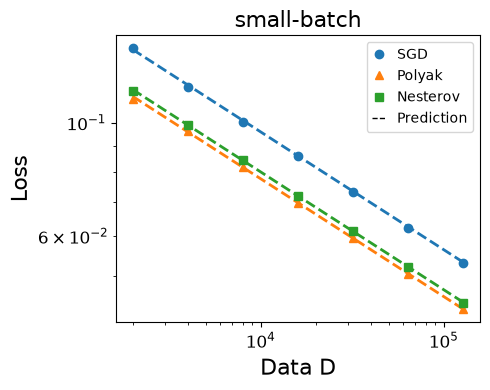

Saved figure: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/small_batch.pdf
Saved figure: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/small_batch.png
Running phase: Large batch (large_batch)
SGD: D=  2000 | B=  11 | K=   181 | tail=   2 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=9.224021e-02 | 0.03s
SGD: D=  4000 | B=  15 | K=   266 | tail=   3 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=8.291332e-02 | 0.05s
SGD: D=  8000 | B=  20 | K=   400 | tail=   4 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=7.248209e-02 | 0.07s


SGD: D= 16000 | B=  26 | K=   615 | tail=   7 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=6.359418e-02 | 0.12s
SGD: D= 32000 | B=  35 | K=   914 | tail=  10 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=5.659190e-02 | 0.17s


SGD: D= 64000 | B=  46 | K=  1391 | tail=  14 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=4.983724e-02 | 0.25s


SGD: D=128000 | B=  62 | K=  2064 | tail=  21 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=4.426184e-02 | 0.37s
HB : D=  2000 | B=  11 | K=   181 | tail=   2 | eta=0.100000 | rho=0.742879 | mean last-1%-steps loss=8.598603e-02 | 0.04s
HB : D=  4000 | B=  15 | K=   266 | tail=   3 | eta=0.100000 | rho=0.772832 | mean last-1%-steps loss=7.360769e-02 | 0.05s
HB : D=  8000 | B=  20 | K=   400 | tail=   4 | eta=0.100000 | rho=0.799296 | mean last-1%-steps loss=6.240330e-02 | 0.08s


HB : D= 16000 | B=  26 | K=   615 | tail=   7 | eta=0.100000 | rho=0.822677 | mean last-1%-steps loss=5.333902e-02 | 0.12s
HB : D= 32000 | B=  35 | K=   914 | tail=  10 | eta=0.100000 | rho=0.843334 | mean last-1%-steps loss=4.520762e-02 | 0.18s


...

HB : D=128000 | B=  62 | K=  2064 | tail=  21 | eta=0.100000 | rho=0.877710 | mean last-1%-steps loss=3.289288e-02 | 0.41s
NAG: D=  2000 | B=  11 | K=   181 | tail=   2 | eta=0.020000 | rho=0.959656 | mean last-1%-steps loss=8.102778e-02 | 0.04s
NAG: D=  4000 | B=  15 | K=   266 | tail=   3 | eta=0.020000 | rho=0.969895 | mean last-1%-steps loss=6.665065e-02 | 0.05s
NAG: D=  8000 | B=  20 | K=   400 | tail=   4 | eta=0.020000 | rho=0.977536 | mean last-1%-steps loss=5.355238e-02 | 0.08s


NAG: D= 16000 | B=  26 | K=   615 | tail=   7 | eta=0.020000 | rho=0.983237 | mean last-1%-steps loss=4.301228e-02 | 0.12s
NAG: D= 32000 | B=  35 | K=   914 | tail=  10 | eta=0.020000 | rho=0.987491 | mean last-1%-steps loss=3.485388e-02 | 0.18s


NAG: D= 64000 | B=  46 | K=  1391 | tail=  14 | eta=0.020000 | rho=0.990666 | mean last-1%-steps loss=2.811196e-02 | 0.28s


NAG: D=128000 | B=  62 | K=  2064 | tail=  21 | eta=0.020000 | rho=0.993035 | mean last-1%-steps loss=2.275997e-02 | 0.40s

Measured and predicted exponents:


,phase,group,label,theory exponent,measured exponent,log-fit intercept,metric
0,large_batch,sgd,SGD,0.177162,0.178707,-1.018842,mean loss over final 1% of steps
1,large_batch,hb,Polyak,0.230769,0.232128,-0.686890,mean loss over final 1% of steps
2,large_batch,nag,Nesterov,0.303870,0.307366,-0.168235,mean loss over final 1% of steps


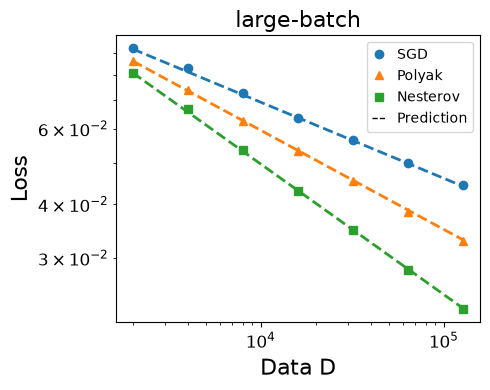

Saved figure: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/large_batch.pdf
Saved figure: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/large_batch.png
Running phase: Super-large batch (super_large_batch)
SGD: D=  2000 | B=  35 | K=    57 | tail=   1 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=1.299104e-01 | 0.01s


SGD: D=  4000 | B=  61 | K=    65 | tail=   1 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=1.243768e-01 | 0.01s
SGD: D=  8000 | B= 106 | K=    75 | tail=   1 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=1.185309e-01 | 0.01s
SGD: D= 16000 | B= 185 | K=    86 | tail=   1 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=1.135416e-01 | 0.02s
SGD: D= 32000 | B= 322 | K=    99 | tail=   1 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=1.088736e-01 | 0.02s
SGD: D= 64000 | B= 560 | K=   114 | tail=   2 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=1.046639e-01 | 0.02s
SGD: D=128000 | B= 975 | K=   131 | tail=   2 | eta=0.300000 | rho=0.000000 | mean last-1%-steps loss=1.006781e-01 | 0.02s
HB : D=  2000 | B=  35 | K=    57 | tail=   1 | eta=0.100000 | rho=0.764059 | mean last-1%-steps loss=1.164225e-01 | 0.01s
HB : D=  4000 | B=  61 | K=    65 | tail=   1 | eta=0.100000 | rho=0.793172 | mean last-1%-steps loss=1.075273e-01 | 0.01s
HB : D=  8000 | 

HB : D= 64000 | B= 560 | K=   114 | tail=   2 | eta=0.100000 | rho=0.877869 | mean last-1%-steps loss=7.868240e-02 | 0.02s


HB : D=128000 | B= 975 | K=   131 | tail=   2 | eta=0.100000 | rho=0.892939 | mean last-1%-steps loss=7.227926e-02 | 0.03s
NAG: D=  2000 | B=  35 | K=    57 | tail=   1 | eta=0.110000 | rho=0.764059 | mean last-1%-steps loss=1.136356e-01 | 0.01s
NAG: D=  4000 | B=  61 | K=    65 | tail=   1 | eta=0.110000 | rho=0.793172 | mean last-1%-steps loss=1.051868e-01 | 0.02s
NAG: D=  8000 | B= 106 | K=    75 | tail=   1 | eta=0.110000 | rho=0.818694 | mean last-1%-steps loss=9.733514e-02 | 0.01s
NAG: D= 16000 | B= 185 | K=    86 | tail=   1 | eta=0.110000 | rho=0.841066 | mean last-1%-steps loss=9.023178e-02 | 0.02s
NAG: D= 32000 | B= 322 | K=    99 | tail=   1 | eta=0.110000 | rho=0.860677 | mean last-1%-steps loss=8.307549e-02 | 0.03s
NAG: D= 64000 | B= 560 | K=   114 | tail=   2 | eta=0.110000 | rho=0.877869 | mean last-1%-steps loss=7.645778e-02 | 0.03s
NAG: D=128000 | B= 975 | K=   131 | tail=   2 | eta=0.110000 | rho=0.892939 | mean last-1%-steps loss=7.030950e-02 | 0.03s

Measured and pr

,phase,group,label,theory exponent,measured exponent,log-fit intercept,metric
0,super_large_batch,sgd,SGD,0.060,0.061565,-1.576018,mean loss over final 1% of steps
1,super_large_batch,hb,Polyak,0.117,0.113977,-1.280778,mean loss over final 1% of steps
2,super_large_batch,nag,Nesterov,0.117,0.115244,-1.295196,mean loss over final 1% of steps


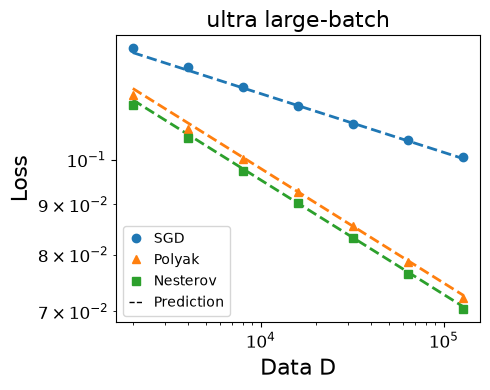

Saved figure: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/super_large_batch.pdf
Saved figure: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/super_large_batch.png

All requested figures:
  small_batch: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/small_batch.pdf
  large_batch: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/large_batch.pdf
  super_large_batch: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases/super_large_batch.pdf


In [7]:
# =============================================================================
# 7. Execute all three phases
# =============================================================================

PHASES_TO_RUN = [
    "small_batch",
    "large_batch",
    "super_large_batch",
]

ALL_PHASE_RESULTS = {}

for phase_name in PHASES_TO_RUN:
    ALL_PHASE_RESULTS[phase_name] = run_phase(phase_name)

print("\nAll requested figures:")
for phase_name in PHASES_TO_RUN:
    print(
        f"  {phase_name}: "
        f"{ALL_PHASE_RESULTS[phase_name]['pdf_path']}"
    )

In [8]:
# =============================================================================
# 8. Combined slope summary
# =============================================================================

COMBINED_SLOPE_SUMMARY = pd.concat(
    [
        ALL_PHASE_RESULTS[phase_name]["slope_summary"]
        for phase_name in PHASES_TO_RUN
    ],
    ignore_index=True,
)

display(COMBINED_SLOPE_SUMMARY)

COMBINED_SLOPE_SUMMARY.to_csv(
    OUTPUT_DIR / "combined_fitted_slopes.csv",
    index=False,
)

print(f"All outputs were saved in: {OUTPUT_DIR.resolve()}")

,phase,group,label,theory exponent,measured exponent,log-fit intercept,metric
0,small_batch,sgd,SGD,0.230769,0.231688,-0.213585,mean loss over final 1% of steps
1,small_batch,hb,Polyak,0.230769,0.229891,-0.439435,mean loss over final 1% of steps
2,small_batch,nag,Nesterov,0.230769,0.230365,-0.403188,mean loss over final 1% of steps
3,large_batch,sgd,SGD,0.177162,0.178707,-1.018842,mean loss over final 1% of steps
4,large_batch,hb,Polyak,0.230769,0.232128,-0.686890,mean loss over final 1% of steps
5,large_batch,nag,Nesterov,0.303870,0.307366,-0.168235,mean loss over final 1% of steps
6,super_large_batch,sgd,SGD,0.060000,0.061565,-1.576018,mean loss over final 1% of steps
7,super_large_batch,hb,Polyak,0.117000,0.113977,-1.280778,mean loss over final 1% of steps
8,super_large_batch,nag,Nesterov,0.117000,0.115244,-1.295196,mean loss over final 1% of steps


All outputs were saved in: /Users/audenhuang/Desktop/Momentum_scaling/Additional_experiments/nag_acc_three_phases
